# Reading a 1D network (Deltares D-Flow FM) with `pyramids-mesh`

Most mesh files describe a **2D surface** — a sheet of triangles or quads. But hydraulic models of rivers and channels store a **1D network**: nodes joined by edges, with *no faces* at all. This notebook reads a Deltares [D-Flow FM](https://www.deltares.nl/en/software/modules/d-flow-flexible-mesh) UGRID `*_net.nc` file — the `korte-woerden` channel schematic — as a 1D network.

**Why this case is special.** pyramids' built-in UGRID reader always builds a 2D `Mesh2d`, whatever topology dimension a file declares — so `UgridDataset.read_file` on a pure-1D file fails (it looks for a face table that is not there). And `Network1d.read_file` only works through a *driver* that returns a network, which the generic `.nc` has none of. The `Network1d` class is therefore **built from arrays**: we read the node coordinates and the edge-node table out of the NetCDF ourselves, then hand them to `Network1d.from_arrays`. That is exactly how the class is meant to be used for a file like this.

## 1. Pin the plotting backend

Figures are rendered through `cleopatra` (matplotlib). So the notebook runs identically under
CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`,
and define a tiny `show()` helper that grabs the current figure, saves it to an in-memory PNG and
embeds it inline. With `Agg` a bare `plt.show()` embeds nothing, so every plot below ends with a
`show()` call instead.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import Network1d, UgridDataset
import numpy as np
import xarray as xr
from pathlib import Path

## 3. Locate the data

The Deltares folder holds several UGRID samples. We use the pure-1D `korte-woerden-1d_FlowFM_net.nc` (network topology, no results).

In [3]:
DATA = Path("../../examples/data")
net_file = DATA / "deltares1d" / "korte-woerden-1d_FlowFM_net.nc"
net_file.name, net_file.exists()

('korte-woerden-1d_FlowFM_net.nc', True)

## 4. Why the normal reader refuses

First, the instructive failure. Pointing `UgridDataset.read_file` at a 1D file raises — the reader tries to build a 2D mesh and finds no `face_node_connectivity`. We catch it so the notebook keeps running, and read the message.

In [4]:
try:
    UgridDataset.read_file(net_file)
except Exception as e:
    print(type(e).__name__, "->", e)

ValueError -> Cannot read face_node_connectivity for mesh 'network'.


That is the signal to treat the file as a **graph**, not a surface.

## 5. Read the network topology from the NetCDF

A Deltares `_net.nc` stores the network under a `network` mesh-topology variable: `network_node_x` / `network_node_y` (node coordinates) and `network_edge_nodes` (the `(n_edge, 2)` edge-node connectivity, `cf_role="edge_node_connectivity"`). It also carries its CRS in `projected_coordinate_system` — EPSG **28992** (Amersfoort / RD New, Dutch national grid, in **metres**). We open the file with xarray and pull the arrays out.

In [5]:
ug = xr.open_dataset(net_file, decode_times=False)
node_x = ug["network_node_x"].values
node_y = ug["network_node_y"].values
edges  = ug["network_edge_nodes"].values
node_x.shape, node_y.shape, edges.shape, edges.dtype

((86,), (86,), (91, 2), dtype('int32'))

86 node coordinates and a `(91, 2)` edge table. UGRID connectivity may be 0- or 1-based; we check the minimum index and shift to 0-based if needed, so the indices address `node_x` safely. (This file is already 0-based: indices run 0–85.)

In [6]:
if edges.min() == 1:
    edges = edges - 1
edges.min(), edges.max(), node_x.size, edges[:3].tolist()

(np.int32(0), np.int32(85), 86, [[0, 1], [0, 2], [3, 0]])

## 6. Build the `Network1d`

`Network1d.from_arrays` wraps the arrays into a network, building the CRS from the EPSG code. The result is a standalone graph object — nodes + edges, **no faces, no centroids, no areas**.

In [7]:
net = Network1d.from_arrays(node_x, node_y, edges, epsg=28992)
{"n_node": net.n_node, "n_edge": net.n_edge,
 "crs": net.crs.name, "epsg": net.crs.to_epsg(),
 "bounds": tuple(round(b, 1) for b in net.bounds)}

{'n_node': 86,
 'n_edge': 91,
 'crs': 'Amersfoort / RD New',
 'epsg': 28992,
 'bounds': (145749.6, 426920.8, 146070.0, 427605.4)}

86 nodes, 91 edges, EPSG:28992. The bounds span only ~320 m × ~685 m — this is a small urban channel schematic. There are more edges than nodes, so the network contains **loops** (it is not a simple tree).

## 7. Explore the graph

A network has no faces, so `n_face` is undefined — accessing it raises by design. Confirm that, then look at properties that *do* make sense for a graph: per-edge Euclidean lengths (in the CRS's metres).

In [8]:
try:
    net.n_face
except Exception as e:
    print("n_face ->", type(e).__name__, str(e)[:70])

n_face -> AttributeError Network1d is a 1D topology (nodes + edges) and has no faces; 'n_face' 


Edge lengths, on the other hand, are a natural graph property. We summarise the 91 edge lengths (metres, since the CRS is projected):

In [9]:
import pandas as pd
L = net.edge_lengths
pd.Series(L).describe().round(2).to_frame("edge_length_m")

,edge_length_m
count,91.00
mean,30.47
std,24.45
min,0.10
25%,19.17
50%,30.28
75%,39.53
max,217.99


91 edges, lengths from a fraction of a metre up to ~218 m, averaging ~30 m — typical for a channel broken into computational segments.

## 8. Draw the network by hand

A `Network1d` has no `plot()` of its own, so we draw it as a graph: loop the edge table, draw each edge as a line segment between its two node coordinates, then scatter the nodes on top. Equal aspect keeps the geometry true (the CRS is in metres).

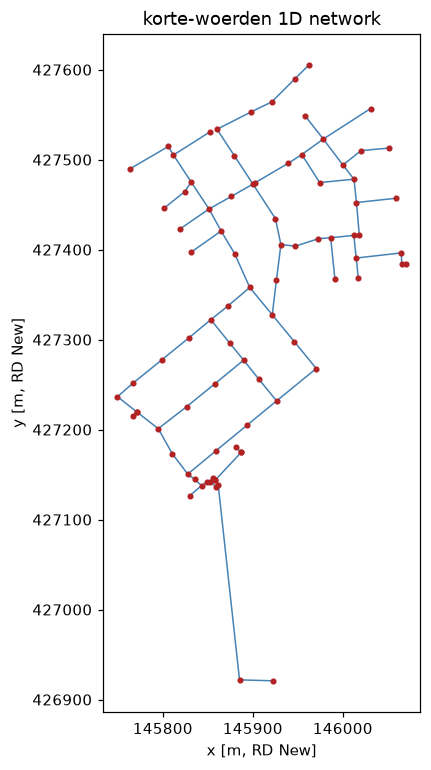

In [10]:
enc = np.asarray(net.edge_node_connectivity.data)
fig, ax = plt.subplots(figsize=(6, 8))
for a, b in enc:
    ax.plot([node_x[a], node_x[b]], [node_y[a], node_y[b]],
            "-", color="steelblue", lw=1.0)
ax.plot(node_x, node_y, "o", color="firebrick", ms=3)
ax.set_aspect("equal"); ax.set_title("korte-woerden 1D network")
ax.set_xlabel("x [m, RD New]"); ax.set_ylabel("y [m, RD New]")
show()

That is the channel schematic: a branching, partly looped network of reaches. Each red dot is a network node; each blue segment is an edge the solver routes flow along.

## 9. The network as vectors

`to_geodataframe()` turns the network into a geopandas `GeoDataFrame` — one **LineString** per edge (`location="edge"`) or one **Point** per node (`location="node"`), CRS-stamped from the network. That is the bridge to the whole vector-GIS ecosystem: spatial joins, export to shapefile/GeoPackage, overlay with other layers.

In [11]:
gdf_edges = net.to_geodataframe(location="edge")
gdf_edges.head()

,geometry
0,"LINESTRING (145843 427137.8, 145830.1 427126.7)"
1,"LINESTRING (145843 427137.8, 145848.7 427141.5)"
2,"LINESTRING (145835.3 427144.7, 145843 427137.8)"
3,"LINESTRING (145827.7 427150.6, 145835.3 427144.7)"
4,"LINESTRING (145858.9 427176.4, 145827.7 427150.6)"


Each row is a LineString. geopandas draws it directly — the same channel network, now as a proper vector layer:

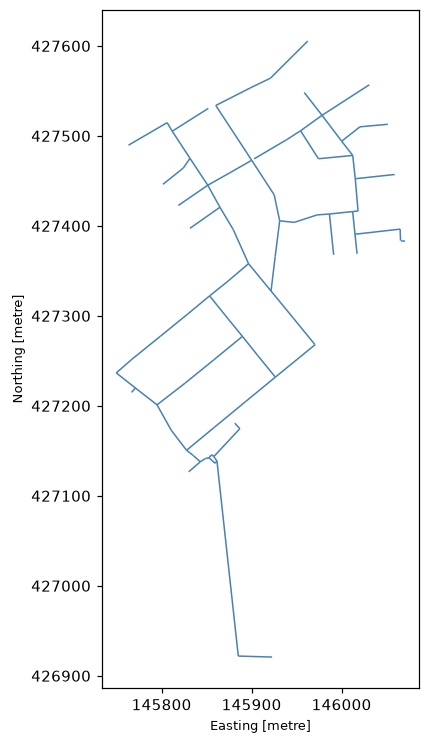

In [12]:
gdf_edges.plot(figsize=(6, 8), color="steelblue", lw=1)
plt.gca().set_aspect("equal"); show()

The node view gives one Point per node; both frames carry the EPSG:28992 CRS:

In [13]:
gdf_nodes = net.to_geodataframe(location="node")
{"edge_rows": len(gdf_edges), "node_rows": len(gdf_nodes),
 "crs": str(gdf_edges.crs)}

{'edge_rows': 91, 'node_rows': 86, 'crs': 'EPSG:28992'}

## 10. Directed ordering (optional)

If the edges are oriented upstream→downstream, a `Network1d` built with `directed=True` can **topologically sort** its nodes for routing. Our file does not guarantee that orientation, so calling `sort()` on the undirected network raises — we show the guard rather than assert a direction the data does not carry.

In [14]:
try:
    net.sort(direction="downstream")
except Exception as e:
    print(type(e).__name__, "->", str(e)[:90])

ValueError -> sort() needs a directed network; construct Network1d(..., directed=True) with edges orient


## Takeaway

A 1D network is a **graph**, not a surface. pyramids keeps it in a dedicated `Network1d` class, and because no built-in driver maps a generic UGRID `.nc` onto a network, you build one with `Network1d.from_arrays(node_x, node_y, edge_nodes, epsg=...)` after reading the arrays yourself. From there you get edge lengths, bounds, nearest-neighbour trees, a `GeoDataFrame` of lines or points, and — for a directed network — topological ordering. There are no faces, areas or centroids, and that is correct: a channel network has none.